# 01 â€” Data Extraction and Preprocessing

Ekstraksi, eksplorasi, dan preprocessing dataset DBLP.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.compute as pc
import pyarrow.parquet as pq

from src import config
from src.viz import MUTED_FILL, SERIES, TEXT_MUTED, apply_style, save

apply_style()
pd.set_option("display.max_colwidth", 80)

## 1. Ekstraksi Data

Sumber: rilis DBLP 2026-11-01 ([doi:10.4230/dblp.xml.2026-11-01](https://doi.org/10.4230/dblp.xml.2026-11-01)),
diunduh pada 18 November 2026. Sel berikut mengunduh data dengan verifikasi MD5 dan mengekstrak
record `inproceedings` ke Parquet, hanya jika hasilnya belum tersedia.

In [2]:
from src.download import download
from src.extract import extract

if not config.INPROC_RAW.exists():
    download()
    extract()

print(config.INPROC_RAW, f"{config.INPROC_RAW.stat().st_size / 1e6:,.0f} MB")

C:\Users\Alfansya\dblp-data\inproceedings-2026-11-01.parquet 406 MB


## 2. Data Understanding

### 2.1 Struktur Dataset

Contoh satu record `inproceedings` hasil ekstraksi.

In [3]:
example = pq.read_table(config.INPROC_RAW, filters=[("key", "==", "conf/cvpr/HeZRS16")]).to_pylist()
pd.Series(example[0]) if example else "Record contoh tidak ditemukan pada rilis ini."

key                                                      conf/cvpr/HeZRS16
mdate                                                           2023-03-24
publtype                                                              None
title                        Deep Residual Learning for Image Recognition.
authors      [Kaiming He, Xiangyu Zhang 0005, Shaoqing Ren, Jian Sun 0001]
year                                                                  2016
booktitle                                                             CVPR
crossref                                                    conf/cvpr/2016
dtype: object

### 2.2 Jenis Publikasi

In [4]:
types = pd.read_csv(config.TABLES_DIR / "dblp_record_types.csv")
types["pct"] = (100 * types["n_records"] / types["n_records"].sum()).round(2)
print(f"Total record: {types['n_records'].sum():,}")
types

Total record: 13,073,341


,record_type,n_records,pct
0,article,4500269,34.42
1,www,4230393,32.36
2,inproceedings,3994940,30.56
3,phdthesis,158401,1.21
4,incollection,71247,0.54
5,proceedings,65785,0.50
6,data,30631,0.23
7,book,21648,0.17
8,mastersthesis,27,0.00


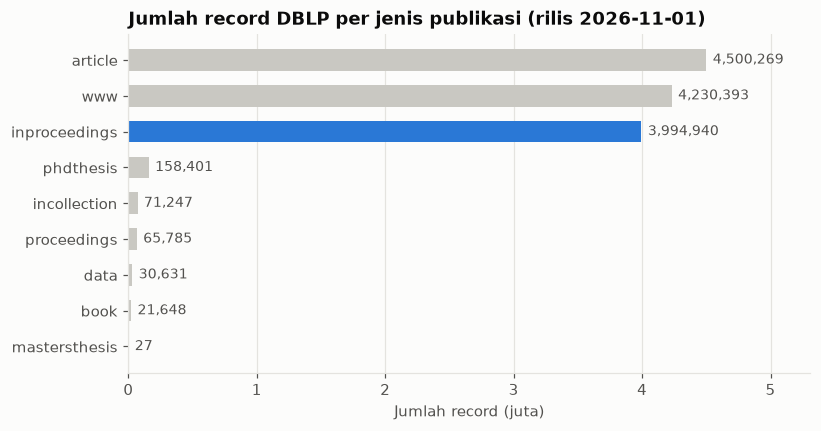

In [5]:
t = types.sort_values("n_records")
colors = [SERIES[0] if r == "inproceedings" else MUTED_FILL for r in t["record_type"]]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(t["record_type"], t["n_records"] / 1e6, color=colors, height=0.6)
for y, v in enumerate(t["n_records"]):
    ax.text(v / 1e6 + 0.05, y, f"{v:,}", va="center", fontsize=9, color=TEXT_MUTED)
ax.set_xlabel("Jumlah record (juta)")
ax.set_title("Jumlah record DBLP per jenis publikasi (rilis 2026-11-01)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, t["n_records"].max() / 1e6 * 1.18)
save(fig, "01_record_types")
plt.show()

### 2.3 Kelengkapan Atribut

Persentase record yang memiliki setiap atribut, per jenis publikasi dan khusus `inproceedings`.

In [6]:
fields = pd.read_csv(config.TABLES_DIR / "dblp_field_presence.csv")
main_fields = ["author", "title", "year", "booktitle", "journal", "crossref", "editor", "publisher", "school"]
fields.pivot(index="field", columns="record_type", values="pct").loc[main_fields].round(1).fillna(0)

record_type,article,book,data,incollection,inproceedings,mastersthesis,phdthesis,proceedings,www
field,,,,,,,,,
author,99.3,88.2,90.1,84.8,99.8,100.0,100.0,0.0,99.9
title,100.0,100.0,90.5,100.0,100.0,100.0,100.0,100.0,99.9
year,100.0,100.0,90.5,100.0,100.0,100.0,100.0,100.0,0.0
booktitle,0.0,8.8,0.0,100.0,100.0,0.0,0.0,99.2,0.0
journal,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
crossref,0.0,0.3,0.0,96.3,99.9,0.0,0.0,0.0,0.1
editor,0.0,11.3,0.0,0.0,0.0,0.0,0.0,74.2,0.0
publisher,0.0,89.8,90.5,0.1,0.0,3.7,5.1,97.2,0.0
school,0.0,11.8,0.0,0.0,0.0,100.0,100.0,0.0,0.0


In [7]:
fields[fields["record_type"] == "inproceedings"].drop(columns="record_type").round(3).reset_index(drop=True)

,field,n_records_with_field,pct
0,title,3994940,100.000
1,year,3994940,100.000
2,url,3994940,100.000
3,booktitle,3994643,99.993
4,crossref,3992331,99.935
5,author,3988862,99.848
6,ee,3857561,96.561
7,pages,3765528,94.257
8,stream,178637,4.472
9,cdrom,8482,0.212


### 2.4 Profil Record `inproceedings`

In [8]:
table = pq.read_table(config.INPROC_RAW, columns=["key", "publtype", "year", "booktitle", "crossref", "authors"])
n_authors = pc.list_value_length(table["authors"]).to_numpy()
inproc = table.drop(["authors"]).to_pandas()
inproc["n_authors"] = n_authors
inproc["year"] = inproc["year"].astype(int)
inproc["prefix"] = inproc["key"].str.split("/").str[0]
del table

in_period = inproc["year"].between(config.YEAR_MIN, config.YEAR_MAX)
pd.Series({
    "Total record inproceedings": len(inproc),
    "Rentang tahun": f"{inproc['year'].min()}â€“{inproc['year'].max()}",
    "Record periode 2015â€“2025": int(in_period.sum()),
    "Seri venue unik (prefix key)": inproc["key"].str.rsplit("/", n=1).str[0].nunique(),
    "Variasi booktitle unik": inproc["booktitle"].nunique(),
}).to_frame("nilai")

,nilai
Total record inproceedings,3994940
Rentang tahun,1951â€“2027
Record periode 2015â€“2025,2003279
Seri venue unik (prefix key),6625
Variasi booktitle unik,15568


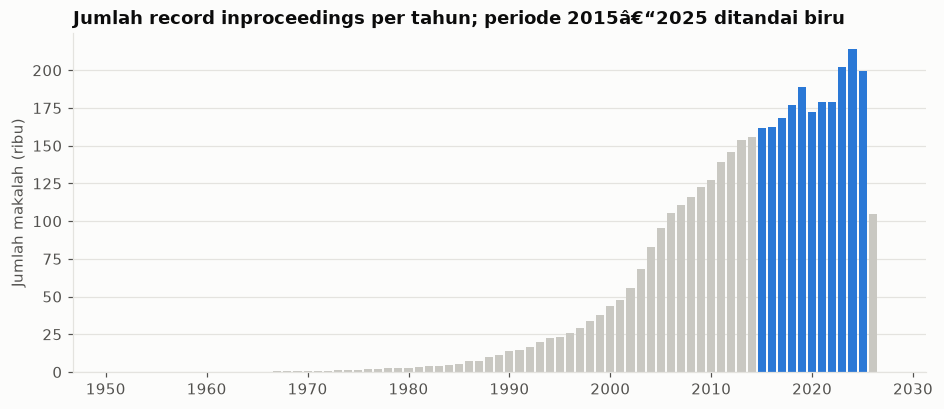

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
n_records,161509,162422,168310,176866,189014,172238,178987,178705,201924,213856,199448


In [9]:
per_year = inproc["year"].value_counts().sort_index()
colors = [SERIES[0] if config.YEAR_MIN <= y <= config.YEAR_MAX else MUTED_FILL for y in per_year.index]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(per_year.index, per_year.values / 1e3, color=colors, width=0.8)
ax.set_ylabel("Jumlah makalah (ribu)")
ax.set_title("Jumlah record inproceedings per tahun; periode 2015â€“2025 ditandai biru")
ax.grid(axis="x", visible=False)
save(fig, "01_inproceedings_per_year")
plt.show()
per_year.loc[config.YEAR_MIN:config.YEAR_MAX].to_frame("n_records").T

Distribusi prefix `key` dan record di luar prefix `conf/`.

In [10]:
pd.DataFrame({
    "semua tahun": inproc["prefix"].value_counts(),
    "2015â€“2025": inproc.loc[in_period, "prefix"].value_counts(),
}).fillna(0).astype(int)

,semua tahun,2015â€“2025
prefix,,
books,51,40
conf,3980692,2000116
journals,14138,3123
persons,1,0
series,57,0
www,1,0


In [11]:
inproc.loc[inproc["prefix"] == "journals", "key"].str.rsplit("/", n=1).str[0].value_counts().head(8).to_frame("n_records")

,n_records
key,
journals/entcs,5833
journals/corr,4453
journals/procedia,2013
journals/jmlr,938
journals/oopsm,257
journals/sigplan,204
journals/tcs,142
journals/sigmetrics,107


Distribusi atribut `publtype` (`withdrawn` = makalah ditarik, `informal` = publikasi informal).

In [12]:
pd.DataFrame({
    "semua tahun": inproc["publtype"].value_counts(dropna=False),
    "2015â€“2025": inproc.loc[in_period, "publtype"].value_counts(dropna=False),
}).fillna(0).astype(int)

,semua tahun,2015â€“2025
publtype,,
edited,2,2
informal,4034,427
informal withdrawn,1,1
withdrawn,1960,1123
NaN,3988943,2001726


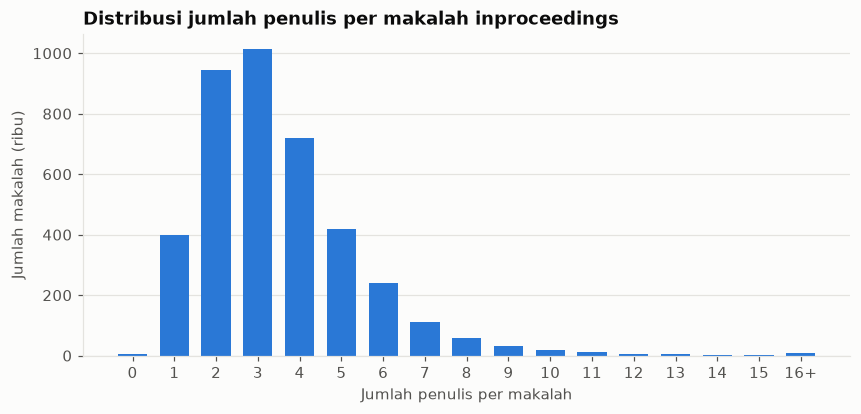

,count,mean,std,min,25%,50%,75%,max
n_authors,3994940.0,3.5,2.11,0.0,2.0,3.0,4.0,279.0


In [13]:
capped = inproc["n_authors"].clip(upper=16)
dist = capped.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(dist.index, dist.values / 1e3, color=SERIES[0], width=0.7)
ax.set_xticks(dist.index, [str(i) if i < 16 else "16+" for i in dist.index])
ax.set_xlabel("Jumlah penulis per makalah")
ax.set_ylabel("Jumlah makalah (ribu)")
ax.set_title("Distribusi jumlah penulis per makalah inproceedings")
ax.grid(axis="x", visible=False)
save(fig, "01_authors_per_paper")
plt.show()
inproc["n_authors"].describe().round(2).to_frame("n_authors").T

## 3. Preprocessing

Setiap langkah dicatat pada objek `funnel` sehingga jumlah record sebelum dan sesudah setiap
tahap dapat ditelusuri.

### 3.1 Seleksi Cakupan Data

Record yang dipertahankan adalah `inproceedings` periode 2015â€“2025 dari seri `conf/`, kecuali
makalah berstatus `withdrawn`.

In [14]:
from src.preprocess import Funnel, select_scope

del inproc
funnel = Funnel()
papers = select_scope(funnel)
funnel.table()

,tahap,langkah,sebelum,sesudah,dihapus
0,Seleksi cakupan,Jenis publikasi inproceedings,13073341,3994940,9078401
1,Seleksi cakupan,Tahun 2015–2025,3994940,2003279,1991661
2,Seleksi cakupan,Seri konferensi/workshop (key conf/),2003279,2000116,3163
3,Seleksi cakupan,Bukan makalah yang ditarik (publtype withdrawn),2000116,1998994,1122


In [15]:
papers["year"].to_pandas().value_counts().sort_index().to_frame("n_records").T

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
n_records,161038,161981,167971,176568,188689,171976,178366,178350,201559,213262,199234


In [16]:
papers["publtype"].to_pandas().fillna("(kosong)").value_counts().to_frame("n_records")

,n_records
publtype,
(kosong),1998599
informal,393
edited,2


### 3.2 Penanganan Missing Values

Makalah tanpa penulis dihapus karena tidak dapat dimasukkan ke transaksi berbasis author.
Makalah tanpa `booktitle` dipertahankan karena venue diturunkan dari `key`.

In [17]:
from src.preprocess import handle_missing, missing_report

missing_report(papers)

,n_missing,pct
authors (tanpa penulis),1131,0.057
authors (nama kosong),0,0.000
title,0,0.000
year,0,0.000
booktitle,190,0.010
crossref,2471,0.124


In [18]:
no_author = papers.filter(pc.equal(pc.list_value_length(papers["authors"]), 0))
no_author.select(["key", "title", "year"]).slice(0, 8).to_pandas()

,key,title,year
0,conf/dac/X22,Frontmatter.,2022
1,conf/clrimg/X22,"Color Imaging XXVII: Displaying, Processing, Hardcopy, and Applications Conf...",2022
2,conf/sigir/X19,Preface: 4th Joint Workshop on BIRNDL at SIGIR 2019.,2019
3,conf/sigir/X20,"BIRDS 2020 - Bridging the Gap between Information Science, Information Retri...",2020
4,conf/sigir/X22,Preface to INRA 2022.,2022
5,conf/transai/X23,Message from the Program Chairs TransAI 2023.,2023
6,conf/transai/X23a,Message from the General Chairs TransAI 2023.,2023
7,conf/csl/X17,"Front Matter, Table of Contents, Preface, Conference Organization, External ...",2017


In [19]:
papers = handle_missing(papers, funnel)
del no_author
missing_report(papers)

,n_missing,pct
authors (tanpa penulis),0,0.000
authors (nama kosong),0,0.000
title,0,0.000
year,0,0.000
booktitle,190,0.010
crossref,2470,0.124


### 3.3 Penghapusan Duplikat

Duplikat diperiksa pada dua tingkat: nama penulis yang tercantum lebih dari sekali dalam satu
makalah, dan makalah yang tercatat lebih dari sekali dengan judul ternormalisasi, tahun, seri
venue, dan penulis yang sama. Dari setiap kelompok duplikat, record dengan `key` terurut pertama
dipertahankan.

In [20]:
from src.preprocess import dedupe_authors, normalized_title, remove_duplicates

papers, n_dup_authors = dedupe_authors(papers)
print(f"Nama penulis ganda yang dihapus: {n_dup_authors}")

Nama penulis ganda yang dihapus: 98


In [21]:
check = pd.DataFrame({
    "key": papers["key"].to_pandas(),
    "title": papers["title"].to_pandas(),
    "booktitle": papers["booktitle"].to_pandas(),
    "t": normalized_title(papers),
    "year": papers["year"].to_pandas(),
    "series": papers["key"].to_pandas().str.rsplit("/", n=1).str[0],
    "authors": pc.binary_join(papers["authors"], "|").to_pandas(),
})
dup = check[check.duplicated(["t", "year", "series", "authors"], keep=False)].sort_values(["t", "key"])
print(f"Record dalam kelompok duplikat: {len(dup):,}")
dup[["key", "title", "year", "booktitle"]].head(10)

Record dalam kelompok duplikat: 2,299


,key,title,year,booktitle
1297185,conf/iticse/PollockABKKOPRW19,1.5 Degrees of Separation: Computer Science Education in the Age of the Anth...,2019,ITiCSE
1297545,conf/iticse/PollockABKKOPRW19a,1.5 Degrees of Separation: Computer Science Education in the Age of the Anth...,2019,ITiCSE-WGR
1219150,conf/huc/OlwalK18,"1D eyewear: peripheral, hidden LEDs and near-eye holographic displays for un...",2018,UbiComp
1220560,conf/huc/OlwalK18a,"1D Eyewear: Peripheral, Hidden LEDs and Near-Eye Holographic Displays for Un...",2018,UbiComp/ISWC Adjunct
1460961,conf/cvpr/GaoG19,2.5D Visual Sound.,2019,CVPR
1453778,conf/cvpr/GaoG19a,2.5D Visual Sound.,2019,CVPR Workshops
1487089,conf/vlsi/SerunjogiS23,"3.125GS/s, 4.9 ENOB, 109 fJ/Conversion Time-Domain ADC for Backplane Interco...",2023,VLSI-SoC
1487032,conf/vlsi/SerunjogiS23a,"3.125GS/s, 4.9 ENOB, 109 fJ/Conversion Time-Domain ADC for Backplane Interco...",2023,VLSI-SoC (Selected Papers)
1904019,conf/icpram/Alexandre15,3D Computer Vision - From Points to Concepts.,2015,ICPRAM (1)
1904293,conf/icpram/Alexandre15a,3D Computer Vision: From Points to Concepts.,2015,ICPRAM (Selected Papers)


In [22]:
dup["series"].value_counts().head(10).to_frame("n_records")

,n_records
series,
conf/dhd,362
conf/wcnc,158
conf/cncl,104
conf/cvpr,77
conf/siggraph,62
conf/chi,58
conf/esws,58
conf/icse,41
conf/isspit,37


In [23]:
del check, dup
papers = remove_duplicates(papers, funnel)
funnel.table()

,tahap,langkah,sebelum,sesudah,dihapus
0,Seleksi cakupan,Jenis publikasi inproceedings,13073341,3994940,9078401
1,Seleksi cakupan,Tahun 2015–2025,3994940,2003279,1991661
2,Seleksi cakupan,Seri konferensi/workshop (key conf/),2003279,2000116,3163
3,Seleksi cakupan,Bukan makalah yang ditarik (publtype withdrawn),2000116,1998994,1122
4,Missing values,Memiliki minimal satu penulis,1998994,1997863,1131
5,Duplikat,Key unik,1997863,1997863,0
6,Duplikat,"Makalah unik (judul, tahun, seri venue, penulis)",1997863,1996703,1160


### 3.4 Normalisasi Nama Author

Nama dirapikan (trim, spasi ganda, Unicode NFC), lalu nama yang hanya berbeda kapitalisasi
digabung ke varian yang paling sering muncul. Nomor homonim DBLP (mis. `Jian Sun 0001`)
dipertahankan, dan varian aksen tidak digabung.

In [24]:
from src.preprocess import merged_case_variants, normalize_authors

merged_case_variants(papers)

,varian,kemunculan
0,"[Aamir Khan, Aamir khan]","[13, 1]"
1,"[Abdallah A. Alshehri, Abdallah A. AlShehri]","[3, 1]"
2,"[Abdel-karim Ajami, Abdel-Karim Ajami]","[11, 1]"
3,"[Abdelfatah Mohamed, AbdelFatah Mohamed]","[2, 1]"
4,"[Abdelkamel Tari, AbdelKamel Tari]","[24, 1]"
5,"[Abdelrahman Abdelgawad, Abdelrahman AbdelGawad]","[1, 1]"
6,"[AbdelRahman Abdou, Abdelrahman Abdou]","[7, 3]"
7,"[AbdElRahman ElSaid, Abdelrahman Elsaid]","[15, 1]"
8,"[Abdulla Alhammadi, Abdulla AlHammadi]","[1, 1]"
9,"[Abdullah A. Al-khatib, Abdullah A. Al-Khatib]","[4, 1]"


In [25]:
papers, author_report = normalize_authors(papers)
papers, n_dup_after_merge = dedupe_authors(papers)
print(f"Nama ganda dalam satu makalah setelah penggabungan: {n_dup_after_merge}")
author_report

Nama ganda dalam satu makalah setelah penggabungan: 1


,tahap,nama_unik,kemunculan_berubah
0,Nama asli,1820355,0
1,"Setelah trim, spasi, dan NFC",1820355,0
2,Setelah penggabungan varian kapitalisasi,1817265,6018


### 3.5 Normalisasi Venue

Venue diturunkan dari seri pada `key` (`conf/<seri>/...`). Nama utama seri adalah `booktitle`
tersering tanpa penanda workshop atau trek pendamping, dengan nomor volume seperti `(1)` diabaikan.
Makalah workshop (booktitle mengandung "Workshop", "@", atau nama utama + "W") dipisah menjadi
venue `<seri>_workshops`. Trek pendamping (Findings, Extended Abstracts, Companion, Posters,
Demos, dan sejenisnya) serta varian nama lain digabung ke venue utama. Seri yang seluruh
booktitle-nya bertanda workshop tetap menjadi venue tersendiri.

In [26]:
from src.preprocess import apply_venues, classify_venues, venue_mapping

venues = classify_venues(papers)
mapping = venue_mapping(venues)
mapping.to_csv(config.TABLES_DIR / "venue_mapping.csv", index=False)

pd.DataFrame({
    "makalah": venues["track"].value_counts(),
    "venue": venues.groupby("track")["venue_id"].nunique(),
})

,makalah,venue
track,,
companion,58048,187
main,1842288,4372
workshop,96367,504


In [27]:
pd.Series({
    "Variasi booktitle": venues["booktitle"].nunique(),
    "Seri (prefix key)": venues["series"].nunique(),
    "Venue setelah normalisasi": venues["venue_id"].nunique(),
    "Venue workshop hasil pemisahan": venues.loc[venues["track"] == "workshop", "venue_id"].nunique(),
}).to_frame("jumlah")

,jumlah
Variasi booktitle,8784
Seri (prefix key),4372
Venue setelah normalisasi,4876
Venue workshop hasil pemisahan,504


In [28]:
examples = ["conf/nips", "conf/cvpr", "conf/acl", "conf/chi", "conf/gecco", "conf/vtc"]
mapping[mapping["series"].isin(examples)].groupby("series").head(6).reset_index(drop=True)

,series,booktitle,track,venue_id,venue_name,n_papers
0,conf/acl,ACL (1),main,acl,ACL,5495
1,conf/acl,ACL (Findings),companion,acl,ACL,3594
2,conf/acl,ACL (2),main,acl,ACL,891
3,conf/acl,ACL,main,acl,ACL,778
4,conf/acl,ACL/IJCNLP (1),main,acl,ACL,571
5,conf/acl,ACL/IJCNLP (Findings),companion,acl,ACL,457
6,conf/chi,CHI,main,chi,CHI,8321
7,conf/chi,CHI Extended Abstracts,companion,chi,CHI,6327
8,conf/chi,AsianCHI@CHI,workshop,chi_workshops,CHI Workshops,89
9,conf/chi,AutomationXP@CHI,workshop,chi_workshops,CHI Workshops,58


In [29]:
papers = apply_venues(papers, venues)
del venues
papers.select(["key", "booktitle", "venue_id", "venue_name", "track"]).slice(0, 5).to_pandas()

,key,booktitle,venue_id,venue_name,track
0,conf/3dic/AgungZT19,3DIC,3dic,3DIC,main
1,conf/3dic/AizawaSNFMF24,3DIC,3dic,3DIC,main
2,conf/3dic/AkiyamaOKFSSTIE16,3DIC,3dic,3DIC,main
3,conf/3dic/AlsukourVFVM0PA24,3DIC,3dic,3DIC,main
4,conf/3dic/AokiTTKK19,3DIC,3dic,3DIC,main
